# Introduction

## The reference data: 

Data Pose - https://github.com/NjtechCVLab/Wi-PoseDataset

In [1]:
%pip install mat73

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# File Preparation and Parse Data to CSV

The data that we receive is in the .mat format, so we need to merge the data into the .pkl for easy to use.

In [2]:
import os, re, glob, time
import numpy as np
import pandas as pd
import scipy.io as sio
import mat73
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

DATA_DIR  = "Wi-Pose/Train"                          # folder containing the .mat files
CSI_VAR   = "CSI"                           # variable names inside the .mat (check with sio.whosmat)
SKEL_VAR  = "SkeletonPoints"
N_WORKERS = min(32, (os.cpu_count() or 4) * 2)   # I/O-bound, so more threads than cores is fine

PATTERN = re.compile(r"^(?P<pose>.+)_(?P<pose_no>\d+)-frame(?P<frame>\d+)\.mat$", re.IGNORECASE)

In [3]:
paths = glob.glob(os.path.join(DATA_DIR, "**", "*.mat"), recursive=True)

index_rows, skipped = [], []
for p in paths:
    m = PATTERN.match(os.path.basename(p))
    if m:
        index_rows.append({
            "pose":    m["pose"],
            "pose_no": int(m["pose_no"]),    # "001" -> 1
            "frame":   int(m["frame"]),      # "012" -> 12
            "path":    p,
        })
    else:
        skipped.append(p)

index_df = pd.DataFrame(index_rows).sort_values(["pose", "pose_no", "frame"]).reset_index(drop=True)
print(f"{len(index_df)} files indexed, {len(skipped)} skipped (name did not match)")
index_df.head()


132847 files indexed, 0 skipped (name did not match)


,pose,pose_no,frame,path
0,bend,1,1,Wi-Pose/Train\bend_001-frame001.mat
1,bend,1,2,Wi-Pose/Train\bend_001-frame002.mat
2,bend,1,3,Wi-Pose/Train\bend_001-frame003.mat
3,bend,1,4,Wi-Pose/Train\bend_001-frame004.mat
4,bend,1,5,Wi-Pose/Train\bend_001-frame005.mat


In [4]:
def load_mat(path):
    """Return (CSI, SkeletonPoints) from one .mat file. Works for v5/v7 and v7.3."""
    d = mat73.loadmat(path, only_include=[CSI_VAR, SKEL_VAR])
    csi, skel = d[CSI_VAR], d[SKEL_VAR]

    if not np.iscomplexobj(csi):
        csi = csi.astype(np.float32)
    else:
        csi = csi.astype(np.complex64)
    return csi, np.asarray(skel, dtype=np.float32)

# Test Function
csi, skel = load_mat(index_df.path[0])
print("CSI:", csi.shape, csi.dtype, "| Skeleton:", skel.shape, skel.dtype)

CSI: (5, 30, 3, 3) float32 | Skeleton: (54,) float32


In [5]:
def worker(row):
    try:
        csi, skel = load_mat(row["path"])
        return {**row, "CSI": csi, "SkeletonPoints": skel}, None
    except Exception as e:
        return None, (row["path"], repr(e))

rows = index_df.to_dict("records")
results, errors = [], []

t0 = time.time()
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    futures = [ex.submit(worker, r) for r in rows]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="Reading .mat"):
        ok, err = fut.result()
        if ok:  results.append(ok)
        if err: errors.append(err)

print(f"Done in {time.time()-t0:.1f}s | loaded {len(results)} | failed {len(errors)}")
if errors:
    print("First failures:", errors[:5])

Reading .mat:   0%|          | 0/132847 [00:00<?, ?it/s]

Done in 603.1s | loaded 132847 | failed 0


# Exporatory Data Analysis



## SkeletonPoints Pose Visualization
To understand the core concept of data, we decided to display the skeleton animation to ensure what data is about.

In [75]:
# Setting up
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

df = pd.read_pickle("dataset.pkl")

N_JOINTS = 18
LAYOUT   = "auto"      # "auto" | "axis_major" | "joint_major"
CONF_MIN = 0.1         # joints below this confidence are treated as missing
SWAP_XY = True   # set False for raw data

# OpenPose-18 / COCO order (verify with the labeled plot)
JOINT_NAMES = ["nose","neck","R_sho","R_elb","R_wri","L_sho","L_elb","L_wri",
               "R_hip","R_knee","R_ank","L_hip","L_knee","L_ank","R_eye","L_eye","R_ear","L_ear"]
BONES = [(1,2),(1,5),(2,3),(3,4),(5,6),(6,7),(1,8),(8,9),(9,10),
         (1,11),(11,12),(12,13),(1,0),(0,14),(14,16),(0,15),(15,17)]

### Required Function

In [74]:
def _parse(a):
    """Turn strings like '[1, 2, ...]' into numeric arrays; pass arrays/lists through."""
    if isinstance(a, str):
        s = a.strip()
        try:
            a = json.loads(s)
        except Exception:
            a = ast.literal_eval(s)
    return np.asarray(a, dtype=np.float32)

def _detect_layout(flat):
    """Pick the layout whose 3rd column looks like confidence (values in 0..1)."""
    ax_c = flat.reshape(3, N_JOINTS)[2]          # axis_major confidences
    jt_c = flat.reshape(N_JOINTS, 3)[:, 2]       # joint_major confidences
    ok = lambda c: np.isfinite(c).all() and (c >= 0).all() and (c <= 1.0001).all()
    if ok(jt_c) and not ok(ax_c): return "joint_major"
    if ok(ax_c) and not ok(jt_c): return "axis_major"
    return "joint_major"                          # ambiguous -> default

def to_kp(a, layout=None):
    """Raw frame (54,) / (18,3) / (3,18) -> (18, 3) array of [x, y, confidence]."""
    layout = layout or LAYOUT
    a = _parse(a)
    if a.shape == (N_JOINTS, 3):
        kp = a
    elif a.shape == (3, N_JOINTS):
        kp = a.T
    else:
        flat = a.ravel()
        if flat.size != N_JOINTS * 3:
            raise ValueError(f"Expected {N_JOINTS*3} values, got {flat.size}")
        if layout == "auto":
            layout = _detect_layout(flat)
        kp = flat.reshape(3, N_JOINTS).T if layout == "axis_major" else flat.reshape(N_JOINTS, 3)
    kp = kp.copy()
    if SWAP_XY:
        kp[:, [0, 1]] = kp[:, [1, 0]]
    return kp

def check_layout(a):
    """Print the 3rd column of both layouts. The right one lies in 0..1."""
    flat = _parse(a).ravel()
    print("axis_major  3rd column:", flat.reshape(3, N_JOINTS).T[:, 2].round(2))
    print("joint_major 3rd column:", flat.reshape(N_JOINTS, 3)[:, 2].round(2))
    print("auto-detected:", _detect_layout(flat))

def visible(kp):
    """Boolean mask of usable joints."""
    return (kp[:, 2] > CONF_MIN) & np.isfinite(kp[:, :2]).all(axis=1)

def get_seq(df, pose, pose_no):
    """Return seq (T, 18, 3) and the frame numbers for one sequence."""
    g = df[(df["pose"] == pose) & (df["pose_no"] == pose_no)].sort_values("frame")
    if g.empty:
        raise ValueError(f"No frames for pose={pose!r}, pose_no={pose_no!r}")
    seq = np.stack([to_kp(a) for a in g["SkeletonPoints"].values])
    return seq, g["frame"].values

def get_limits(seq, pad=20):
    """Fixed axis limits for the whole sequence. y is returned inverted (image coords)."""
    m = (seq[..., 2] > CONF_MIN) & np.isfinite(seq[..., :2]).all(axis=-1)
    pts = seq[m][:, :2]
    if len(pts) == 0:
        return (0, 1), (1, 0)
    return ((pts[:, 0].min() - pad, pts[:, 0].max() + pad),
            (pts[:, 1].max() + pad, pts[:, 1].min() - pad))

def plot_kp(kp, ax=None, color="tab:blue", label=False, alpha=1.0, bones=BONES):
    """kp: (18, 3) = x, y, conf. y points down (image coordinates)."""
    ax = ax or plt.gca()
    ok = visible(kp)
    xy = kp[:, :2]
    ax.scatter(xy[ok, 0], xy[ok, 1], s=22, color=color, alpha=alpha)
    if bones:
        for a, b in bones:
            if ok[a] and ok[b]:
                ax.plot(xy[[a, b], 0], xy[[a, b], 1], color=color, lw=1.8, alpha=alpha)
    if label:
        for i in np.where(ok)[0]:
            ax.text(xy[i, 0], xy[i, 1], str(i), fontsize=8)
    ax.set_aspect("equal")
    return ax

axis_major  3rd column: [0.86 0.66 0.72 0.87 0.85 0.6  0.31 0.37 0.49 0.72 0.71 0.39 0.62 0.48
 0.91 0.07 0.94 0.01]
joint_major 3rd column: [1.9855e+02 2.0121e+02 3.4486e+02 3.3194e+02 1.2662e+02 4.3499e+02
 3.6039e+02 3.1767e+02 3.5071e+02 3.1607e+02 2.9840e+02 3.4794e+02
 7.2000e-01 6.0000e-01 4.9000e-01 3.9000e-01 9.1000e-01 1.0000e-02]
auto-detected: axis_major
(110, 18, 3) | frames 1 to 110
x range: 0.39722073 554.33185 | y range: 0.06914207 554.1154
confidence range: 0.01 436.04


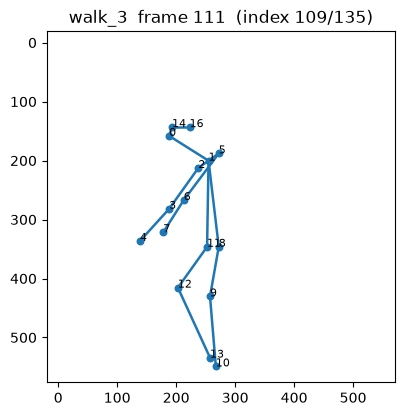

In [76]:
def show_frame(df, pose, pose_no, t=0, frame=None, label=True):
    """t = index in the sequence; or pass frame=<real frame number> instead."""
    seq, frames = get_seq(df, pose, pose_no)
    if frame is not None:
        idx = np.where(frames == frame)[0]
        if len(idx) == 0:
            raise ValueError(f"Frame {frame} not found. Available: {frames[0]}..{frames[-1]}")
        t = int(idx[0])
    if not 0 <= t < len(seq):
        print(f"t={t} out of range (sequence has {len(seq)} frames), using last frame")
        t = len(seq) - 1
    xlim, ylim = get_limits(seq)
    fig, ax = plt.subplots(figsize=(4.5, 5.5))
    plot_kp(seq[t], ax, label=label)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_title(f"{pose}_{pose_no}  frame {frames[t]}  (index {t}/{len(seq)-1})")
    plt.show()

# --- sanity checks ---
check_layout(df.SkeletonPoints.iloc[0])
seq, frames = get_seq(df, "bend", 1)
print(seq.shape, "| frames", frames[0], "to", frames[-1])
print("x range:", np.nanmin(seq[..., 0]), np.nanmax(seq[..., 0]),
      "| y range:", np.nanmin(seq[..., 1]), np.nanmax(seq[..., 1]))
print("confidence range:", seq[..., 2].min().round(2), seq[..., 2].max().round(2))

show_frame(df, "walk", 3, t=109)          # by index
# show_frame(df, "walk", 3, frame=109)    # or by actual frame number                     # (T, 18, 3) with the last axis = up

### Animating the frame sequence

In [83]:
def animate_seq(df, pose, pose_no, interval=60, label=False):
    seq, frames = get_seq(df, pose, pose_no)
    xlim, ylim = get_limits(seq)
    fig, ax = plt.subplots(figsize=(4.5, 5.5))

    def update(i):
        ax.clear()
        plot_kp(seq[i], ax, label=label)
        ax.set_xlim(xlim); ax.set_ylim(ylim)
        ax.set_title(f"{pose}_{pose_no}  frame {frames[i]}")

    anim = FuncAnimation(fig, update, frames=len(seq), interval=interval)
    plt.close(fig)                         # avoid a duplicate static figure
    return HTML(anim.to_jshtml())

In [85]:
animate_seq(df, "run", 1)

## Noise Reduction

In [ ]:
# TODO: Working On EDA

# Data Understanding 

# Noise Reduction -> Find the way to remove the point noise

# Grouping Data -> Same Pose 

# Dimension Reduction (to display in 2D ....)


# Model Training

In [ ]:
# Which model?, feature selection, how to evaluate the model, how to improve accuracy of model

# Test and Implementation